# 10주차 학생 워크북: 교통 데이터의 시각화
인공지능과 데이터 활용 · 동서울대학교 · 2시간

## 무엇을 완성하나요?
2017년 2호선 6개 역의 실제 보관 데이터를 읽고 **역별 막대그래프, 시간대별 승하차 선그래프, 역×시간 히트맵**을 만듭니다. 결과를 숫자로 설명하고 서울시 AI 인구 예측 서비스와 비교표를 완성합니다. 선택 실습에서는 이용량 예측을 수행합니다.

**완성 순서:** 사본 저장 → 데이터 확인 → 그래프 3개 → 결과 질문 → AI 서비스 비교 → 제출 ZIP.

Google Colab에서 파일 → Drive에 사본 저장을 누른 후 위에서 아래로 ▶ 실행합니다. 런타임은 CPU면 충분합니다. 기본 라이브러리 pandas·matplotlib·scikit-learn만 사용합니다. 런타임을 초기화했다면 1단계부터 다시 실행합니다.

[실습 CSV 내려받기(Drive)](https://drive.google.com/file/d/1XvhVGkqu-oswxe6zbXM2Dd1S3kZoL7Rw/view) · [가공 전 발췌본](https://drive.google.com/file/d/1AzSbAk1GbJd1gnsciW7daGEUjcNH3g-w/view) · [전체 수업 폴더](https://drive.google.com/drive/folders/1QAzK6zvNbnmODChS9MrjmB9AnERzdPgn)

### 완성 결과 미리보기
아래 그림은 기본 조건(201709, 강남)의 히트맵 완성 예시입니다. 6개 역을 같은 색 기준으로 비교합니다.

![완성 히트맵 예시](https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week10/results/03_station_hour_heatmap.png)

자료는 2017년 역사 데이터입니다. 최근 교통 현황을 나타내지 않습니다. 월 누적을 달력일로 나눈 평균이므로 특정 평일 출퇴근 상황으로 단정하지 않습니다.


## 1. 데이터 불러오기 (10분)
기본은 수업 GitHub의 고정 CSV를 자동으로 읽습니다. API 키나 Drive 마운트가 필요 없습니다. 자동 연결이 안 되면 노션에 연결된 Drive의 `subway_2017_tidy.csv`를 내려받아 아래 셀에서 업로드합니다.

실행 후 **1,728행, 9열 / 12개월 / 6개 역**이 나와야 합니다. 원자료 보관 경로와 가공 방법은 SOURCES.md를 확인하세요.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
OUT = Path('week10_outputs')
OUT.mkdir(exist_ok=True)
DATA_URL = 'https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week10/data/subway_2017_tidy.csv'
local = Path('data/subway_2017_tidy.csv')
try:
    df = pd.read_csv(local if local.exists() else DATA_URL, dtype={'month':str})
except Exception as exc:
    print('자동 읽기 실패:', type(exc).__name__, 'Drive 제공 CSV를 업로드하세요.')
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('subway_2017_tidy.csv 한 개만 업로드하세요.')
    import io
    df = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))), dtype={'month':str})
required = ['month','line','station','hour','boarding','alighting','calendar_days','boarding_per_day','alighting_per_day']
assert set(required).issubset(df.columns), '열 이름을 확인하세요. 원자료가 아니라 tidy 파일을 사용합니다.'
assert df.shape == (1728, 9), '수업 제공본과 행·열 수가 다릅니다.'
assert not df[required].isna().any().any(), '결측값 확인'
assert not df.duplicated(['month','line','station','hour']).any(), '중복 키 확인'
assert df[['boarding','alighting']].ge(0).all().all(), '음수 확인'
assert set(df.hour)==set(range(24))
assert df.month.nunique()==12 and df.station.nunique()==6
print('데이터 크기:', df.shape, '개월:', df.month.nunique(), '역:', df.station.nunique())
display(df.head())


데이터 크기: (1728, 9) 개월: 12 역: 6
    month line station  ...  calendar_days  boarding_per_day  alighting_per_day
0  201701  2호선      시청  ...             31          2.741935           0.161290
1  201701  2호선      시청  ...             31         45.838710          58.064516
2  201701  2호선      시청  ...             31         74.225806         502.516129
3  201701  2호선      시청  ...             31        184.677419        2797.903226
4  201701  2호선      시청  ...             31        271.451613        6351.612903

[5 rows x 9 columns]


## 2. 분석 조건과 집계 (10분)
처음에는 `MONTH='201709'`, `STATION='강남'`을 유지합니다. 그래프를 완성한 뒤 월과 역을 바꾸고 2~5단계를 다시 실행하여 비교하세요. 역 목록은 아래 셀에 출력됩니다.

월 길이가 다르므로 `boarding_per_day`를 사용합니다. 승하차 합은 역 이용 활동량이며 열차 안에 남아 있는 승객 수가 아닙니다.


In [2]:
MONTH = '201709'
STATION = '강남'
print('사용 가능한 역:', sorted(df.station.unique()))
assert MONTH in set(df.month), '201701~201712 중 선택'
assert STATION in set(df.station), '출력된 역 이름을 복사하세요.'
selected = df[df.month.eq(MONTH)].copy()
selected['activity_per_day'] = selected.boarding_per_day + selected.alighting_per_day
ranking = selected.groupby('station')['activity_per_day'].sum().sort_values(ascending=False)
hour_order = list(range(4,24)) + list(range(4))
hour_labels = [f'{h:02d}' for h in hour_order]
english = {'강남':'Gangnam','잠실(송파구청)':'Jamsil','신림':'Sillim','신도림':'Sindorim','홍대입구':'Hongik Univ.','시청':'City Hall'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11})
print('월:', MONTH, '선택역:', STATION)
display(ranking.rename('승하차 활동량(명/일)').round(1).to_frame())


          승하차 활동량(명/일)
station               
강남            202520.0
잠실(송파구청)      171791.2
홍대입구          159271.2
신림            141924.1
신도림           126140.1
시청             48218.4

사용 가능한 역: ['강남', '시청', '신도림', '신림', '잠실(송파구청)', '홍대입구']
월: 201709 선택역: 강남


## 3. 역별 막대그래프 (10분)
막대 길이는 그 달의 **일평균 승차+하차 활동량**입니다. 6개 역 안에서만 순위를 해석합니다. 한글 폰트 설치 없이 실행되도록 그림은 영문 역명을 사용합니다.

확인: 제목에 연월, 가로축에 명/일, 세로축에 6개 역이 나타납니다. 어느 역이 가장 큰가요? `01_station_bar.png`가 저장됩니다.


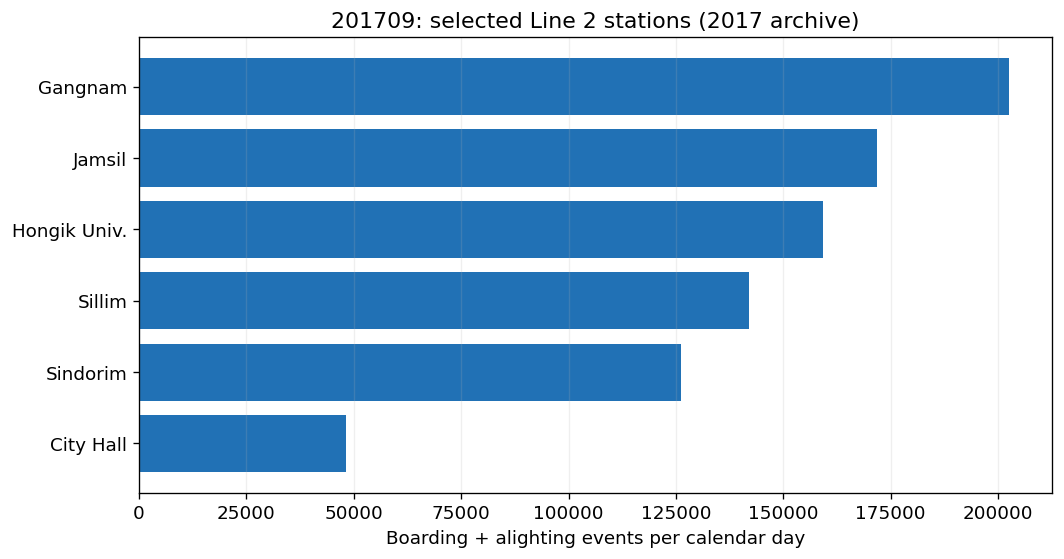

In [3]:
fig, ax = plt.subplots(figsize=(9,4.8))
plot_rank = ranking.sort_values()
ax.barh([english[s] for s in plot_rank.index], plot_rank.values, color='#2171b5')
ax.set(xlabel='Boarding + alighting events per calendar day', title=f'{MONTH}: selected Line 2 stations (2017 archive)')
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(OUT/'01_station_bar.png', dpi=150)
plt.show()


## 4. 시간대별 선그래프 (15분)
역 하나를 선택해 승차와 하차를 두 선으로 비교합니다. 시간은 04시부터 다음 03시까지 정렬합니다.

확인: 두 선과 범례가 나타납니다. 최고점은 승차·하차가 같은 시각인가요? 08은 08~09시를 뜻합니다. 아래 피크 시간과 그래프를 대조하세요.


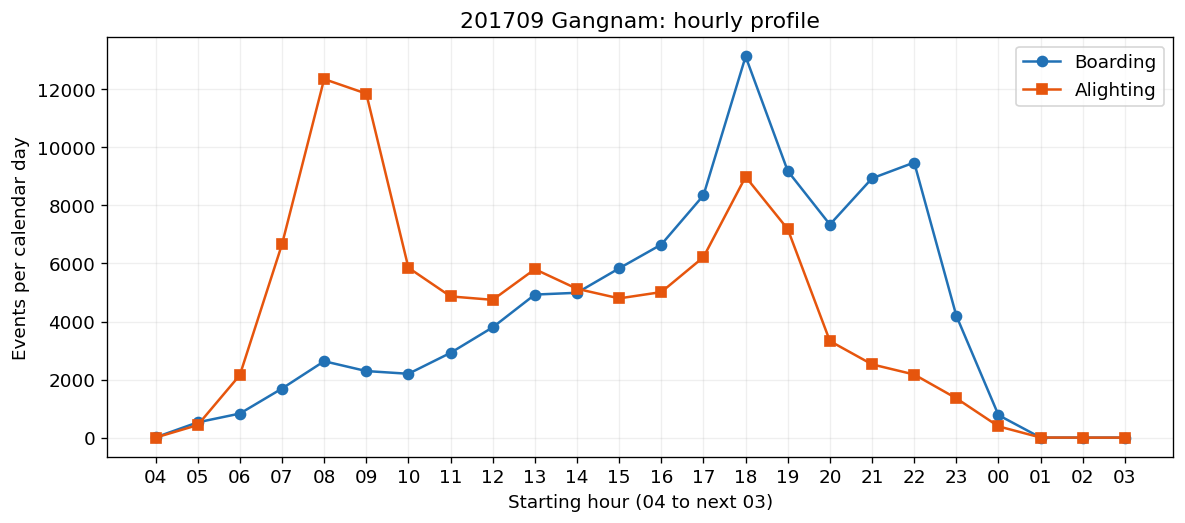

승차 피크: 18~19시, 13,133.5명/일
하차 피크: 08~09시, 12,353.8명/일


In [4]:
profile = selected[selected.station.eq(STATION)].set_index('hour').reindex(hour_order)
fig, ax = plt.subplots(figsize=(10,4.5))
x = np.arange(24)
ax.plot(x, profile.boarding_per_day, marker='o', label='Boarding', color='#2171b5')
ax.plot(x, profile.alighting_per_day, marker='s', label='Alighting', color='#e6550d')
ax.set_xticks(x, hour_labels)
ax.set(xlabel='Starting hour (04 to next 03)', ylabel='Events per calendar day', title=f'{MONTH} {english[STATION]}: hourly profile')
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'02_hourly_lines.png', dpi=150)
plt.show()
peak_board = int(profile.boarding_per_day.idxmax())
peak_alight = int(profile.alighting_per_day.idxmax())
print(f'승차 피크: {peak_board:02d}~{(peak_board+1)%24:02d}시, {profile.boarding_per_day.max():,.1f}명/일')
print(f'하차 피크: {peak_alight:02d}~{(peak_alight+1)%24:02d}시, {profile.alighting_per_day.max():,.1f}명/일')


## 5. 역×시간 히트맵 (15분)
같은 색 기준으로 6개 역의 승차 일평균을 비교합니다. 진한 색은 이용량이 많은 구간입니다. 각 역을 최대값으로 정규화한 비율 그림이 아니므로 역 사이의 절대량을 비교할 수 있습니다.

확인: 6행×24열이며 색 막대의 단위는 명/일입니다. 출근·퇴근이라고 보이는 패턴을 찾되 월별 전체 요일 평균이라는 한계를 함께 적으세요.


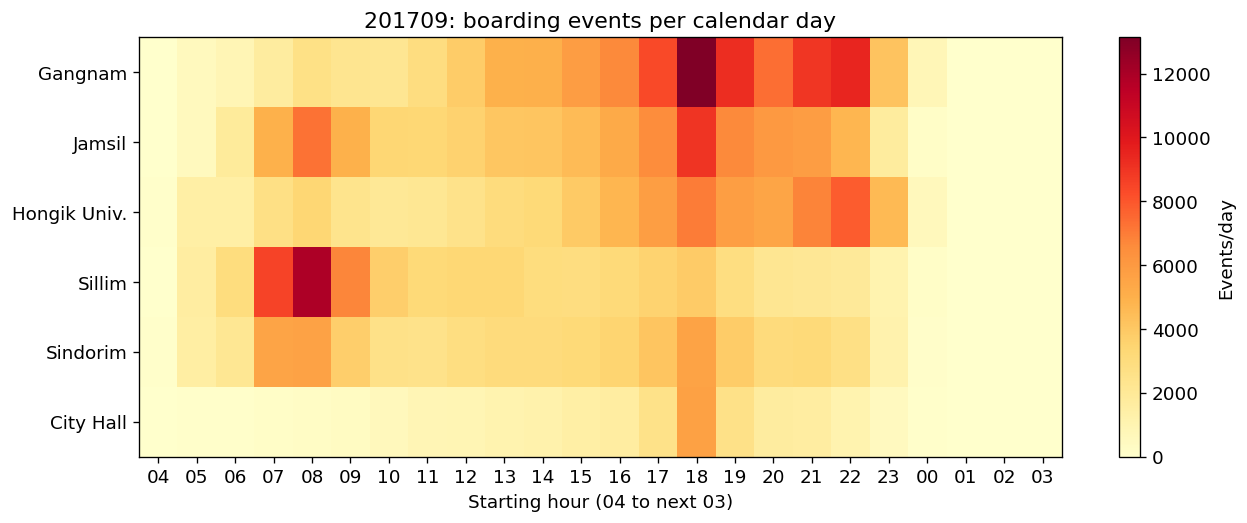

    month station  ... boarding_peak_per_day  alighting_peak_per_day
0  201709      강남  ...          13133.466667                 12353.8

[1 rows x 7 columns]

In [5]:
heat = selected.pivot(index='station', columns='hour', values='boarding_per_day').reindex(index=ranking.index, columns=hour_order)
assert heat.shape == (6,24) and not heat.isna().any().any()
fig, ax = plt.subplots(figsize=(11,4.5))
im = ax.imshow(heat, aspect='auto', cmap='YlOrRd', vmin=0)
ax.set_xticks(range(24), hour_labels)
ax.set_yticks(range(6), [english[s] for s in heat.index])
ax.set(xlabel='Starting hour (04 to next 03)', title=f'{MONTH}: boarding events per calendar day')
fig.colorbar(im, ax=ax, label='Events/day')
fig.tight_layout(); fig.savefig(OUT/'03_station_hour_heatmap.png', dpi=150)
plt.show()
summary = pd.DataFrame([{'month':MONTH,'station':STATION,'top_station_in_sample':ranking.index[0],
 'peak_boarding_hour':peak_board,'peak_alighting_hour':peak_alight,
 'boarding_peak_per_day':profile.boarding_per_day.max(),'alighting_peak_per_day':profile.alighting_per_day.max()}])
summary.to_csv(OUT/'analysis_summary.csv',index=False,encoding='utf-8-sig')
display(summary)


## 6. 분석 결과를 완성하세요 (10분)
아래 답변 셀에서 따옴표 안을 본인의 문장으로 바꾸세요. 실행 결과 표와 그래프에서 근거 숫자를 가져옵니다. 정답을 외우는 과제가 아니라 결과를 읽고 제한된 범위에서 설명하는 과제입니다.

| 질문 | 답에 포함할 것 |
|---|---|
| Q1. 표본에서 이용 활동량이 가장 큰 역은? | 월, 역, 승하차 합계/일 |
| Q2. 선택역의 승차·하차 피크는? | 각각 시간대와 명/일 |
| Q3. 막대와 히트맵의 역할 차이는? | 전체 규모와 시간 패턴 |
| Q4. 이 데이터로 평일 08시 실제 혼잡을 확정할 수 있나? | 월 집계·요일 부재·정원 부재 |
| Q5. 조건을 바꾸면 어떤 차이가 보이나? | 다른 역 또는 월, 원 조건과 비교한 숫자 |


In [6]:
answers = {
 'Q1':f'{MONTH}, 표본 최상위 {ranking.index[0]}, {ranking.iloc[0]:,.1f}명/일(승하차 활동량)',
 'Q2':f'{STATION}, 승차 {peak_board:02d}시 {profile.boarding_per_day.max():,.1f}명/일, 하차 {peak_alight:02d}시 {profile.alighting_per_day.max():,.1f}명/일',
 'Q3':'막대는 6역의 하루 총 활동량 규모, 히트맵은 승차가 많은 역과 시간의 조합을 보여준다.',
 'Q4':'월별 자료라 평일만 분리할 수 없고 열차 정원·현재 재차인원이 없어서 열차 혼잡률을 계산할 수 없다.',
 'Q5':f'같은 월 홍대입구의 승차 피크는 {int(selected[selected.station.eq("홍대입구")].set_index("hour").boarding_per_day.idxmax()):02d}시이다. 강남의 승차 피크 {peak_board:02d}시와 비교할 수 있다.'
}
(OUT/'student_answers.json').write_text(__import__('json').dumps(answers,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(answers,name='예시 답변').to_frame())


                                                예시 답변
Q1           201709, 표본 최상위 강남, 202,520.0명/일(승하차 활동량)
Q2         강남, 승차 18시 13,133.5명/일, 하차 08시 12,353.8명/일
Q3  막대는 6역의 하루 총 활동량 규모, 히트맵은 승차가 많은 역과 시간의 조합을 보여준다.
Q4  월별 자료라 평일만 분리할 수 없고 열차 정원·현재 재차인원이 없어서 열차 혼잡률을...
Q5  같은 월 홍대입구의 승차 피크는 22시이다. 강남의 승차 피크 18시와 비교할 수 있다.

## 7. 실제 AI 혼잡도 예측 서비스와 비교 (20분)
1. [서울 실시간 도시데이터](https://data.seoul.go.kr/SeoulRtd/)를 엽니다.
2. 검색에서 `강남역` 등 선택역과 대응하는 장소를 찾아 실시간 인구와 향후 전망을 확인합니다. 지도에는 역 주변 영역이 표시됩니다.
3. 조회한 날짜·시간(KST), 장소, 데이터 갱신 시각, 표시된 예측 시각·값/범위·등급을 기록합니다. 화면에 없는 값은 추측하지 말고 '미제공'으로 기록합니다.
4. 과거 2017년 월별 역 이용량과 오늘의 장소 인구 예측은 단위·시점이 달라 같은 값이어야 할 이유가 없습니다. 정확도 경쟁은 하지 않습니다.
5. 접속이 어려우면 아래 공식 매뉴얼의 고정 설명으로 비교표를 작성할 수 있습니다. 이때 관찰 방식은 '매뉴얼 기반'으로 적고 실제 관찰값 칸은 '미조회'로 둡니다.

**미리 준비된 읽기 자료:** Drive의 SOURCES.md와 AI_SERVICE_COMPARISON.md. [공식 매뉴얼 V8.5](https://data.seoul.go.kr/SeoulRtd/downloads/실시간_도시데이터_매뉴얼.pdf)의 PDF 34번째 페이지: 최근 인구·날짜·시간으로 다음 12시간 인구를 예측하는 Seq2Seq 구조를 설명합니다. 급격한 인파 변화에 오차가 있을 수 있습니다.

| 비교 항목 | 수업 시각화 | 서울시 AI 서비스 |
|---|---|---|
| 입력 | 2017년 월·역·시간별 교통카드 승하차 | 실시간 인구 및 날짜·시간 특성 |
| 공간 | 2호선 역별 태그 집계 | 지도에 정의된 역 주변 장소 영역 |
| 출력 | 과거 월의 시간대별 일평균 이용량 | 향후 인구 및 혼잡도 전망 |
| 시간 | 월별, 시각화는 1시간 구간 | 향후 12시간 예측(매뉴얼 기준) |
| 해석 한계 | 요일·열차·정원·현재 상황 없음 | 예측 오차·이벤트 급변·공간 집계 오차 |

**작성:** 두 출력이 달라질 수 있는 이유 2개, 출발 시간 선택에 활용하는 방법 1개, 실제 서비스 정확도를 평가하려면 추가로 필요한 데이터 1개를 적습니다.


In [7]:
service_record = {
 '관찰방식':'매뉴얼 기반', '조회일시_KST':'2026-11-05 자료 준비 시 확인', '장소':'역 주변 장소 일반',
 '데이터갱신시각':'미조회','예측대상시각':'미조회','예측인구_범위':'미조회','예측혼잡등급':'미조회',
 '차이가나는이유_2개':'2017년과 현재라는 시점 차이. 역 교통카드 태그와 주변 영역의 체류 인구라는 대상 차이.',
 '출발시간선택에활용하는방법':'역 이용 패턴을 참고하고 방문 당일 주변 장소의 시간별 전망을 추가 확인해 출발 시간을 정한다.',
 '정확도평가에필요한추가데이터':'같은 장소·예측시점·목표시각으로 저장한 공식 예측값과 이후 같은 정의의 관측값'
}
(OUT/'ai_service_comparison.json').write_text(__import__('json').dumps(service_record,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(service_record,name='매뉴얼 기반 예시').to_frame())


                                                        매뉴얼 기반 예시
관찰방식                                                       매뉴얼 기반
조회일시_KST                                    2026-11-05 자료 준비 시 확인
장소                                                     역 주변 장소 일반
데이터갱신시각                                                       미조회
예측대상시각                                                        미조회
예측인구_범위                                                       미조회
예측혼잡등급                                                        미조회
차이가나는이유_2개      2017년과 현재라는 시점 차이. 역 교통카드 태그와 주변 영역의 체류 인구라는 대...
출발시간선택에활용하는방법   역 이용 패턴을 참고하고 방문 당일 주변 장소의 시간별 전망을 추가 확인해 출발 시...
정확도평가에필요한추가데이터        같은 장소·예측시점·목표시각으로 저장한 공식 예측값과 이후 같은 정의의 관측값

## 8. 선택 심화: AI 이용량 예측과 기준값 비교 (추가 15~20분)
기본 수업 120분 이후 또는 과제로 수행합니다. **예측 목표는 월·역·시간별 달력일평균 승차 이용량(명/일)**입니다. 차량 혼잡도 예측이 아닙니다.

2017년 1~9월로 학습하고, 9월 말에 10~12월을 한 번에 예상한다고 가정합니다. 기준값은 같은 역·시간의 9월 일평균을 그대로 유지합니다. Random Forest는 월·시간·역으로 학습합니다. 무작위 분할 대신 월 순서로 나눠 미래 데이터가 학습에 섞이지 않게 합니다. scikit-learn은 Colab 기본 환경에 포함되어 있습니다.

MAE는 평균 절대 오차입니다. 작을수록 좋지만 AI가 기준값보다 반드시 좋지는 않습니다. 1년·6역의 작은 표본, 일평균 평활화, 제한된 특징 때문에 실제 운영 성능으로 일반화할 수 없습니다.


                   model  MAE_events_per_day
0  September persistence              222.52
1          Random Forest              219.82

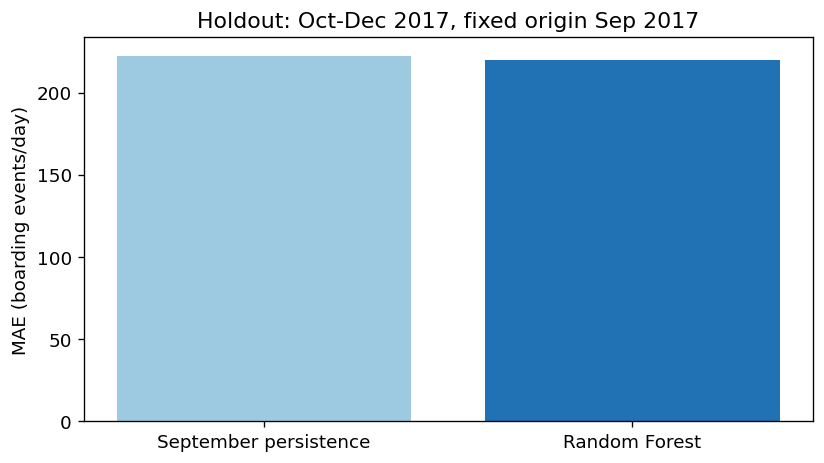

학습기간: 201701 201709 학습행: 1296 평가행: 432


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
model_df = df.copy()
model_df['month_num'] = model_df.month.str[4:].astype(int)
train = model_df[model_df.month.le('201709')].copy()
test = model_df[model_df.month.gt('201709')].copy()
assert train.month.max() < test.month.min()
features = ['station','hour','month_num']
pre = ColumnTransformer([('station',OneHotEncoder(handle_unknown='ignore'),['station'])],remainder='passthrough')
model = make_pipeline(pre,RandomForestRegressor(n_estimators=100,min_samples_leaf=2,random_state=42,n_jobs=1))
model.fit(train[features],train.boarding_per_day)
test['AI'] = model.predict(test[features])
base = train[train.month.eq('201709')].set_index(['station','hour']).boarding_per_day
test['baseline'] = [base.loc[(s,h)] for s,h in zip(test.station,test.hour)]
metrics = pd.DataFrame({'model':['September persistence','Random Forest'],
 'MAE_events_per_day':[mean_absolute_error(test.boarding_per_day,test.baseline),mean_absolute_error(test.boarding_per_day,test.AI)]})
display(metrics.round(2))
metrics.to_csv(OUT/'prediction_metrics.csv',index=False)
test.to_csv(OUT/'prediction_details.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(metrics.model,metrics.MAE_events_per_day,color=['#9ecae1','#2171b5'])
ax.set(ylabel='MAE (boarding events/day)',title='Holdout: Oct-Dec 2017, fixed origin Sep 2017')
fig.tight_layout();fig.savefig(OUT/'04_prediction_mae.png',dpi=150);plt.show()
print('학습기간:',train.month.min(),train.month.max(),'학습행:',len(train),'평가행:',len(test))


## 9. 제출 파일 만들기 (5분)
1. Q1~Q5와 서비스 비교 셀의 '직접 작성' 안내를 본인 답변으로 바꿔 다시 실행합니다.
2. 이름과 학번은 아래 셀에 적습니다. 학번은 문자열로 유지하세요.
3. 아래 셀을 실행하면 결과 폴더와 ZIP을 만듭니다. Colab 왼쪽 파일 목록에서 ZIP을 내려받습니다.
4. 파일 → 다운로드 → .ipynb 다운로드로 본인 답변과 실행 결과가 포함된 노트북도 저장합니다.
5. 수업에서 안내한 제출처에 **본인 ipynb + 결과 ZIP**을 제출합니다. ZIP에 PNG 3장, 분석 요약 CSV, 답변 JSON, 서비스 비교 JSON이 있는지 확인하세요. 선택 심화를 실행했다면 예측 결과도 포함됩니다.

| 확인 | 기준 |
|---|---|
| 데이터 | 1,728행, 2017년·6역의 범위 명시 |
| 그래프 | 제목·축·단위·범례 및 시간 순서 확인 |
| 해석 | 숫자 근거 및 표본·집계 한계 명시 |
| 비교 | 서비스 대상/단위 차이와 관찰 방식 기록 |
| 제출 | ipynb와 ZIP 모두 저장 |


In [9]:
student = {'학번':'본인학번','성명':'본인성명','분반':'본인분반'}
(OUT/'student_info.json').write_text(__import__('json').dumps(student,ensure_ascii=False,indent=2),encoding='utf-8')
needed=['01_station_bar.png','02_hourly_lines.png','03_station_hour_heatmap.png','analysis_summary.csv','student_answers.json','ai_service_comparison.json']
assert all((OUT/f).exists() for f in needed), '앞 단계부터 실행하세요.'
import shutil
zip_path = shutil.make_archive('Week10_submission','zip',OUT)
print('제출 ZIP:',zip_path)
print('Colab 왼쪽 파일 목록에서 ZIP을 내려받고, ipynb도 별도로 다운로드하세요.')


제출 ZIP: /workspace/scratch/8b35bbba6f49/Week10/Week10_submission.zip
Colab 왼쪽 파일 목록에서 ZIP을 내려받고, ipynb도 별도로 다운로드하세요.
